
# Proposed Intervention Framework

This final notebook proposes a simple, interpretable framework for identifying students who may benefit from additional academic support. Building on the predictive modelling results, the framework combines estimated non-completion risk with first-period academic performance (G1) to assign students to three intervention priority groups.

Two criteria are used:

- **Predicted non-completion risk:** A probability $\geq$ 20%, estimated using the selected L1-regularised logistic regression model.
- **Early academic attainment:** A first-period grade of 8 or below (G1 $\leq$ 8).

Students are assigned to intervention priorities according to the following rules:

| Priority | Criteria |
|---|---|
| **High** | Both thresholds are met. |
| **Moderate** | Exactly one threshold is met. |
| **Low** | Neither threshold is met. |

The proposed framework is intended as an illustrative decision-support tool rather than a validated intervention policy.


### Imports and Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from preprocessing_utils import full_preprocessing_pipeline

RISK_THRESHOLD = 0.20
G1_CUTOFF = 8
G3_CUTOFF = 8

priority_order = ["High", "Moderate", "Low"]

palette = {
    "Low": "#8FD5A6",
    "Moderate": "#FFD180",
    "High": "#F28B82"
}

### Data Loading and Train-Test Split

The dataset is divided into training (80%) and test (20%) subsets, stratified by non-completion status to preserve the class distribution.

In [2]:
df = pd.read_csv(os.path.join("..", "data", "raw", "Math-Students.csv"))
df["is_non_completer"] = (df["G3"] == 0).astype(int)

train_raw, test_raw = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["is_non_completer"]
)

y_train = train_raw["is_non_completer"]


### Model Implementation

The logistic regression model is reconstructed using a custom transformer within a **scikit-learn Pipeline**. This integrates preprocessing and prediction into a single, reusable workflow, simplifying future implementation and ensuring consistent transformations across new data.

A dedicated function then combines predicted risk probabilities with G1 attainment to assign intervention priorities.


In [3]:
class RiskPreprocessor(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        _, self.scaler_ = full_preprocessing_pipeline(
            X, model_type="risk"
        )
        return self

    def transform(self, X):
        X = full_preprocessing_pipeline(
            X, model_type="risk", scaler=self.scaler_
        ).copy()

        X["support_gap_engineered"] = X["failures"] * (1 - X["schoolsup"])
        X["social_distraction_engineered"] = X["goout"] * (1 - X["studytime"])
        X["lifestyle_risk_engineered"] = X["age"] * X["alc_avg"]
        X["health_burden_engineered"] = X["alc_avg"] * (1 - X["health"])

        features = [
            "support_gap_engineered", "alc_avg", "schoolsup", "age",
            "lifestyle_risk_engineered", "romantic", "paid", "failures",
            "traveltime", "Pedu_max", "goout", "social_distraction_engineered",
            "health", "freetime", "health_burden_engineered", "G1"
        ]

        return X[features]


risk_pipeline = Pipeline([
    ("preprocessing", RiskPreprocessor()),
    ("model", LogisticRegression(
        C=1, penalty="l1", solver="liblinear",
        random_state=42, max_iter=2000
    ))
])


def assign_priorities(data, probabilities):
    results = data[["G1"]].copy()

    results["risk_probability"] = probabilities
    results["risk_flag"] = probabilities >= RISK_THRESHOLD
    results["g1_flag"] = results["G1"] <= G1_CUTOFF

    risk = results["risk_flag"]
    g1 = results["g1_flag"]

    results["intervention_priority"] = np.select(
        [risk & g1, risk | g1],
        ["High", "Moderate"],
        default="Low"
    )

    return results


### Intervention Priority Assignment and Evaluation

The fitted pipeline generates non-completion risk probabilities for students in the withheld test set. These predictions are combined with G1 attainment to assign intervention priorities according to the criteria.

The resulting groups are evaluated against observed final grades (G3).

Group sizes, low-attainment rates, non-completion counts and mean final grades are compared to assess how effectively the framework distinguishes students with different academic outcomes. Final grade distributions are also visualised across the three priority groups.


,students,low_attainers,non_completers,mean_G3,low_attainment_rate_pct
intervention_priority,,,,,
High,10,10,5,3.30,100.0
Moderate,17,13,3,6.76,76.5
Low,53,1,0,12.40,1.9


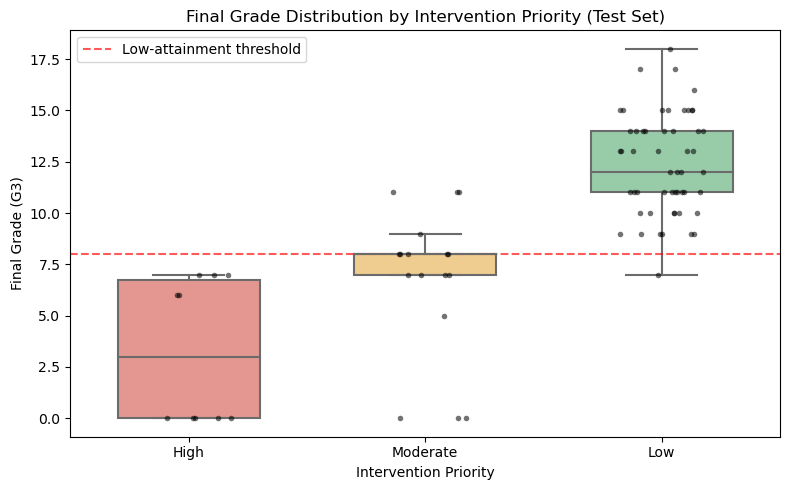

In [4]:
risk_pipeline.fit(train_raw, y_train)

test_probs = risk_pipeline.predict_proba(test_raw)[:, 1]
test_flags = assign_priorities(test_raw, test_probs)

test_results = test_raw[["G3"]].join(test_flags)

test_results["low_attainment"] = test_results["G3"] <= G3_CUTOFF
test_results["non_completion"] = test_results["G3"] == 0

test_summary = (
    test_results.groupby("intervention_priority")
    .agg(
        students=("G3", "size"),
        low_attainers=("low_attainment", "sum"),
        non_completers=("non_completion", "sum"),
        mean_G3=("G3", "mean")
    )
    .reindex(priority_order)
)

test_summary["low_attainment_rate_pct"] = (
    100 * test_summary["low_attainers"] / test_summary["students"]
)

display(test_summary.round({
    "mean_G3": 2,
    "low_attainment_rate_pct": 1
}))

fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=test_results,
    x="intervention_priority",
    y="G3",
    order=priority_order,
    hue="intervention_priority",
    palette=palette,
    dodge=False,
    showfliers=False,
    width=0.6,
    ax=ax
)

sns.stripplot(
    data=test_results,
    x="intervention_priority",
    y="G3",
    order=priority_order,
    color="black",
    alpha=0.55,
    jitter=0.18,
    size=4,
    ax=ax
)

ax.axhline(
    G3_CUTOFF,
    color="red",
    linestyle="--",
    alpha=0.65,
    label="Low-attainment threshold"
)

ax.set(
    xlabel="Intervention Priority",
    ylabel="Final Grade (G3)",
    title="Final Grade Distribution by Intervention Priority (Test Set)"
)

handles, labels = ax.get_legend_handles_labels()
ax.legend(
    [h for h, label in zip(handles, labels)
     if label == "Low-attainment threshold"],
    ["Low-attainment threshold"]
)

plt.tight_layout()
plt.show()


## Results and Discussion

The proposed framework demonstrates a clear distinction in academic outcomes across the three intervention priority groups. Notably, the high- and moderate-priority groups collectively capture **23 of the 24 low-attainment cases** in the test set, whilst the low-priority group demonstrates substantially stronger academic performance.

The framework offers a potentially useful practical advantage over relying on G1 alone: by combining early attainment with predicted non-completion risk, it identifies a smaller, higher-risk group. This may be particularly valuable in educational settings where limited resources make providing intensive support to all lower-attaining students impractical.

However, the high-priority group does not capture every student who eventually experiences non-completion or very low attainment. The missed students are instead captured within the moderate-priority group, which also flags some students who achieve relatively strong results. This highlights a trade-off between concentrating resources on the highest-risk students and ensuring that all students who need support are identified. In practice, the moderate-priority group could therefore serve as a secondary screening stage, where students receive further assessment to determine whether they require targeted intervention.

Ultimately, the framework is exploratory. Small group sizes and the use of G3 = 0 as a proxy for non-completion limit the reliability and generalisability of the findings.

Further validation and consideration of practical and ethical implications would be necessary before implementation in a real educational setting.
